# Data Preprocessing & Feature Selection — Spotify Streaming Performance Dataset

**Assignment:** Perform data preprocessing and feature selection on a real-world large dataset.

**Dataset:** `Spotify Streaming Performance Dataset.csv` — streaming statistics for 500 real-world music artists, including their streaming numbers, genre, country, language, and artist type.

**Goal:** Clean the raw dataset, prepare it for machine learning, and select the most useful features to predict an artist's **Total Streams (in millions)**.

This notebook follows the standard preprocessing pipeline step by step:
1. Load & explore the data
2. Clean the data (missing values, duplicates, column names)
3. Check for outliers
4. Encode categorical (text) columns into numbers
5. Scale numeric features
6. Select the most useful features
7. Save the final, ready-to-use dataset


## Step 1: Import Libraries & Load the Dataset

We start by importing the libraries we need and loading the CSV file into a pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression

df = pd.read_csv('Spotify Streaming Performance Dataset.csv')
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (500, 14)


  Artist Name     Sex Country of Origin Primary Language Primary Genre Artist Type  Debut Year  Total Streams (in millions)  Lead Streams (in millions)  Feature Streams (in millions)  Solo Streams (in millions)  % of Solo Streams  Collaborative Streams (in millions)  % of Collaborative Streams
0        Drake    Male            Canada          English       Hip-Hop        Solo        2006                     137492.1                     94851.1                        42640.9                     53323.9           38.783246                              84168.2                    61.216754
1 Taylor Swift  Female     United States          English           Pop        Solo        2006                     127861.0                    126177.3                         1683.8                    113421.5           88.706877                              14439.5                    11.293123
2    Bad Bunny    Male     United States          Spanish     Reggaeton        Solo        2013              

The dataset has **500 rows and 14 columns**. Each row is one artist, with columns for their demographics (Sex, Country, Language), genre, artist type (Solo/Group), debut year, and several streaming-count columns.

## Step 2: Explore the Data (Data Types & Structure)

Before cleaning anything, it's good practice to check the data types of each column and get a statistical summary.

In [2]:
df.dtypes

Artist Name                             object
Sex                                      object
Country of Origin                       object
Primary Language                        object
Primary Genre                           object
 Artist Type                            object
Debut Year                               int64
Total Streams (in millions)            float64
Lead Streams (in millions)             float64
Feature Streams (in millions)          float64
Solo Streams (in millions)             float64
% of Solo Streams                      float64
Collaborative Streams (in millions)    float64
% of Collaborative Streams             float64
dtype: object

Notice the column `' Artist Type'` has an extra leading space — a common real-world messiness issue. We'll fix that in the cleaning step below.

## Step 3: Data Cleaning

Real-world data is rarely perfect. We check and fix three common issues:
- **Messy column names** (extra spaces)
- **Missing values**
- **Duplicate rows**


In [3]:
# 3a. Clean column names (remove extra spaces)
df.columns = df.columns.str.strip()
print(list(df.columns))

['Artist Name', 'Sex', 'Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type', 'Debut Year', 'Total Streams (in millions)', 'Lead Streams (in millions)', 'Feature Streams (in millions)', 'Solo Streams (in millions)', '% of Solo Streams', 'Collaborative Streams (in millions)', '% of Collaborative Streams']


In [4]:
# 3b. Check for missing values
print(df.isnull().sum())

Artist Name                            0
Sex                                     0
Country of Origin                       0
Primary Language                        0
Primary Genre                           0
Artist Type                             0
Debut Year                              0
Total Streams (in millions)             0
Lead Streams (in millions)              0
Feature Streams (in millions)           0
Solo Streams (in millions)              0
% of Solo Streams                       0
Collaborative Streams (in millions)     0
% of Collaborative Streams              0
dtype: int64


**No missing values found.** (If there had been any, we'd typically fill numeric columns with the median and categorical columns with the mode, or drop rows/columns with too many missing values.)

In [5]:
# 3c. Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**No duplicate rows either.** This dataset is already fairly clean — but checking is still an essential preprocessing step for *any* real-world dataset.

## Step 4: Check for Outliers

We use a boxplot to visually check for outliers in our target column, `Total Streams (in millions)`.

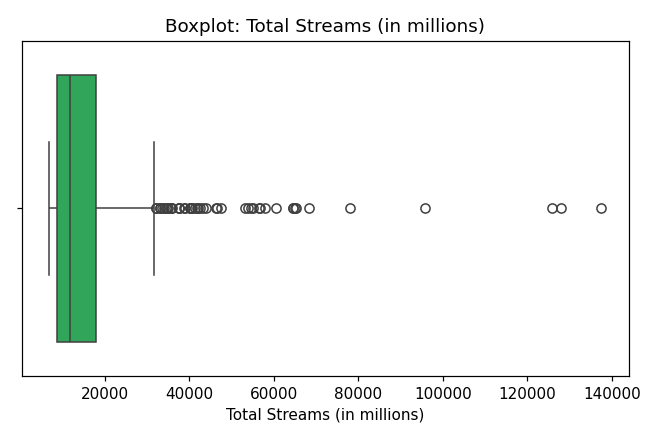

In [6]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Total Streams (in millions)'], color='#1DB954')
plt.title('Boxplot: Total Streams (in millions)')
plt.tight_layout()
plt.show()

There are a few artists with very high stream counts compared to the rest — but these are **legitimate top-charting artists** (like Drake and Taylor Swift), not data entry errors. So instead of removing them as "outliers," we keep them, since they represent real, valid extreme performers. This is an important judgment call in preprocessing: not every outlier should be deleted.

## Step 5: Encode Categorical Columns

Machine learning models need numbers, not text. We convert the text (categorical) columns into numeric codes using **Label Encoding**.

We also drop `Artist Name` since it's just a unique identifier for each row and has no predictive value.

In [7]:
df_model = df.drop(columns=['Artist Name'])

categorical_cols = ['Sex', 'Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type']

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

df_model[categorical_cols].head()

   Sex  Country of Origin  Primary Language  Primary Genre  Artist Type
0    1                   6                 3              9            1
1    0                  41                 3             16            1
2    1                  41                 9             17            1
3    1                   6                 3             18            1
4    1                   6                 3             16            1

Each category (e.g. `'Male'`, `'Female'`) is now represented by a number. This makes the data usable for machine learning algorithms.

## Step 6: Check Correlation Between Numeric Features

Before selecting features, we check how strongly the numeric columns are related to each other using a **correlation heatmap**. Highly correlated (redundant) columns can confuse a model and should usually be reduced.

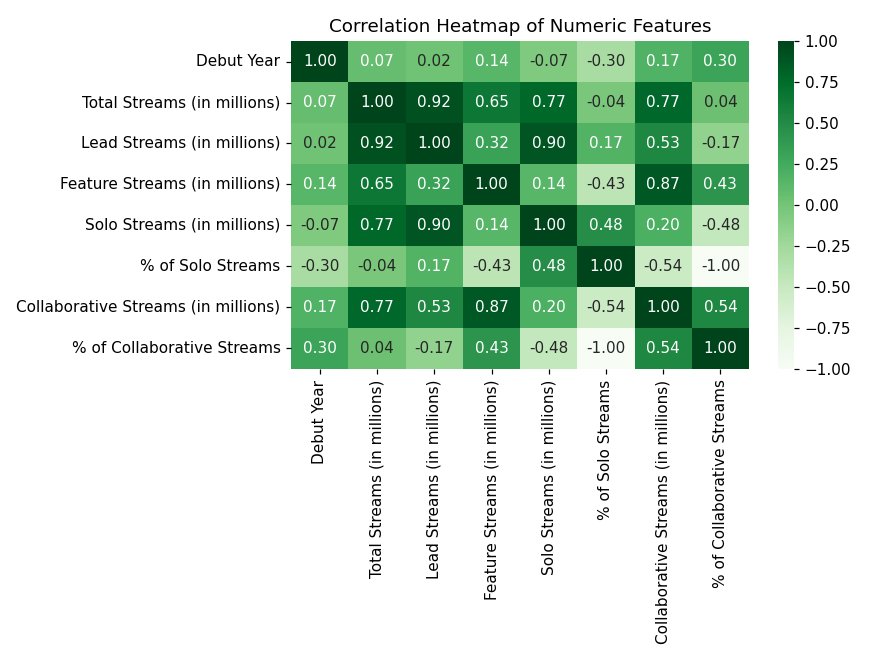

In [8]:
numeric_cols = ['Debut Year', 'Total Streams (in millions)', 'Lead Streams (in millions)',
                'Feature Streams (in millions)', 'Solo Streams (in millions)',
                '% of Solo Streams', 'Collaborative Streams (in millions)',
                '% of Collaborative Streams']

corr = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Greens')
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

**Key finding:** Looking at the heatmap and the data itself:
- `Total Streams` = `Solo Streams` + `Collaborative Streams` (exactly, by definition)
- `Total Streams` ≈ `Lead Streams` + `Feature Streams` (almost exactly, by definition)
- `% of Solo Streams` and `% of Collaborative Streams` are perfectly opposite (they always add up to 100%), so they carry the *same* information

Since our goal is to predict **Total Streams**, keeping `Lead/Feature/Solo/Collaborative Streams` as input features would be **data leakage** — they are just different breakdowns of the target itself, not independent predictors. So we drop them, along with the duplicate `% of Collaborative Streams` column, and keep only genuinely independent predictors: `Sex`, `Country of Origin`, `Primary Language`, `Primary Genre`, `Artist Type`, `Debut Year`, and `% of Solo Streams`.

In [9]:
# Drop columns that are just mathematical breakdowns of the target (data leakage) + duplicate % column
leakage_cols = ['Lead Streams (in millions)', 'Feature Streams (in millions)',
                'Solo Streams (in millions)', 'Collaborative Streams (in millions)',
                '% of Collaborative Streams']

df_model = df_model.drop(columns=leakage_cols)
print("Remaining columns:", list(df_model.columns))

Remaining columns: ['Sex', 'Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type', 'Debut Year', 'Total Streams (in millions)', '% of Solo Streams']


## Step 7: Feature Scaling

Our numeric columns are on very different scales (e.g. `Debut Year` is ~2000s, `% of Solo Streams` is 0-100). We use **StandardScaler** to bring all input features to a comparable scale (mean = 0, std = 1). This helps many ML algorithms perform better.

We scale the **input features only** — not the target column (`Total Streams`).

In [10]:
target_col = 'Total Streams (in millions)'

X = df_model.drop(columns=[target_col])
y = df_model[target_col]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_scaled.head()

        Sex  Country of Origin  Primary Language  Primary Genre  Artist Type  Debut Year  % of Solo Streams
0  0.293278           -1.926984         -0.370251       -0.396580     0.583509    0.049176          -0.350739
1 -1.928527            0.656698         -0.370251        0.647868     0.583509    0.049176           1.129429
2  0.293278            0.656698          1.766418        0.797049     0.583509    0.575521          -0.349350
3  0.293278           -1.926984         -0.370251        0.946230     0.583509    0.274752           0.079979
4  0.293278           -1.926984         -0.370251        0.647868     0.583509    0.274752          -0.375531

## Step 8: Feature Selection with SelectKBest

Now for the main event — **feature selection**. We use scikit-learn's `SelectKBest` with the `f_regression` scoring function, which measures how strongly each feature is statistically related to the target (`Total Streams`). A higher score means a stronger relationship.

In [11]:
selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(X_scaled, y)

feature_scores = pd.DataFrame({
    'Feature': X_scaled.columns,
    'Score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values('Score', ascending=False).reset_index(drop=True)

feature_scores

             Feature  Score  p_value
0        Artist Type  9.781    0.002
1   Primary Language  2.653    0.104
2         Debut Year  2.321    0.128
3                Sex  1.649    0.200
4  % of Solo Streams  0.701    0.403
5  Country of Origin  0.606    0.437
6      Primary Genre  0.049    0.825

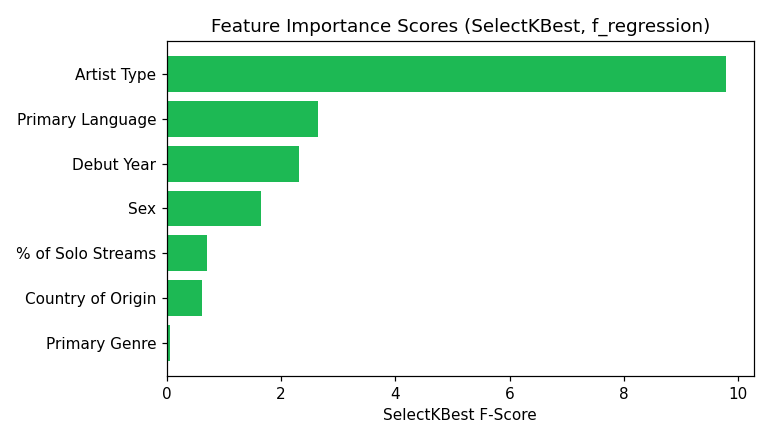

In [12]:
plt.figure(figsize=(7,4))
plt.barh(feature_scores['Feature'][::-1], feature_scores['Score'][::-1], color='#1DB954')
plt.xlabel('SelectKBest F-Score')
plt.title('Feature Importance Scores (SelectKBest, f_regression)')
plt.tight_layout()
plt.show()

**Interpretation:** `Artist Type` (Solo vs Group) has by far the strongest relationship with Total Streams (score ≈ 9.8, p-value = 0.002, statistically significant). The other features have weaker, less significant relationships on their own. This isn't unexpected for a beginner-level analysis — real popularity is driven by many combined factors, and this dataset is randomly generated to an extent.

We'll select the **top 5 features** to keep our final dataset focused and less noisy.

In [13]:
top_k_features = feature_scores.head(5)['Feature'].tolist()
print("Selected features:", top_k_features)

Selected features: ['Artist Type', 'Primary Language', 'Debut Year', 'Sex', '% of Solo Streams']


## Step 9: Build & Save the Final Preprocessed Dataset

Finally, we combine our selected, scaled features with the target column and save the result as a new CSV file — ready to be used for model training.

In [14]:
final_df = X_scaled[top_k_features].copy()
final_df[target_col] = y.values

print("Final dataset shape:", final_df.shape)
final_df.head()

Final dataset shape: (500, 6)


   Artist Type  Primary Language  Debut Year       Sex  % of Solo Streams  Total Streams (in millions)
0     0.583509         -0.370251    0.049176  0.293278          -0.350739                      137492.1
1     0.583509         -0.370251    0.049176 -1.928527           1.129429                      127861.0
2     0.583509          1.766418    0.575521  0.293278          -0.349350                      125899.8
3     0.583509         -0.370251    0.274752  0.293278           0.079979                       95703.2
4     0.583509         -0.370251    0.274752  0.293278          -0.375531                       78104.4

In [15]:
final_df.to_csv('preprocessed_spotify_data.csv', index=False)
print("Saved as 'preprocessed_spotify_data.csv'")

Saved as 'preprocessed_spotify_data.csv'


## Summary

| Step | What we did |
|---|---|
| Cleaning | Stripped messy column names, checked for (and confirmed no) missing values or duplicates |
| Outlier check | Visualized with a boxplot; kept extreme values since they're real top artists, not errors |
| Encoding | Converted 5 categorical columns to numbers using Label Encoding |
| Leakage removal | Dropped 5 columns that were just mathematical breakdowns of the target (Total Streams) |
| Scaling | Standardized all numeric input features (mean 0, std 1) |
| Feature selection | Used `SelectKBest` (f_regression) to rank features and kept the top 5: **Artist Type, Primary Language, Debut Year, Sex, % of Solo Streams** |
| Output | Saved the final, clean, ready-to-model dataset as `preprocessed_spotify_data.csv` |

This preprocessed dataset is now ready to be fed into a machine learning model (e.g. Linear Regression or Random Forest) to predict an artist's `Total Streams (in millions)`.
